# 🎛️ VGAIN SCAN ANALYSIS


**🔍 Step-by-Step**

**Interactive debugging**



In [ ]:
%load_ext autoreload
%autoreload 2

from waffles.coldboxVD.march_26.analysis.utils import *
import kaleido

[raw_root_reader.py]: Could not import ROOT module. 'pyroot' library options will not be available.
[input_utils.py]: Could not import ROOT module. 'pyroot' library options will not be available.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
base = "/afs/cern.ch/user/m/mamollov/waffles/src/waffles/coldboxVD/march_26_mariya/analysis/input/json_files"
print(os.listdir(base))

['vgain_parameters_M5_ch19_bias0000_led800.json', 'vgain_parameters_M5_ch18_bias0000_led830.json', 'vgain_parameters_M6_ch20_bias0000_led930.json', 'vgain_parameters_M6_ch21_bias0000_led920.json', 'vgain_parameters_M5_ch16_bias0000_led830.json', 'vgain_parameters_M5_ch17_bias0000_led800.json', 'vgain_parameters_M6_ch18_bias0000_led930.json', 'vgain_parameters_M6_ch19_bias0000_led920.json', 'vgain_parameters_M5_ch20_bias0000_led830.json', 'vgain_parameters_M5_ch21_bias0000_led800.json', 'vgain_parameters_M6_ch22_bias0000_led930.json', 'vgain_parameters_M6_ch23_bias0000_led920.json']


In [ ]:
#  Cathode analysis

membrane = 'M6'
channel = 19
led = 920
bias = 0
output_files_comment = ''

vgain = 2300
input_file = f"/eos/experiment/neutplatform/protodune/experiments/ColdBoxVD/March2026run/PoF/BiasVGainScan_ch16to19/afe2bias_{bias:04d}/vgain_{vgain:04d}/led_{led}_ch{channel}/channel_{channel}.dat"
## -- from input file --

with open(f"input/json_files/vgain_parameters_{membrane}_ch{channel}_bias{bias:04d}_led{led}.json", "r") as f:
    dict_params_all = json.load(f)
dict_params_all = {int(k): v for k, v in dict_params_all.items()}

dict_params = dict_params_all[vgain] 

In [ ]:

###Example of dict params with comments

# dict_params = {
#     #Baseline is computed from timetick 0 to baseline_timeticks_limit
#     "baseline_timeticks_limit": 130, 

#     # For the integral computation, you have two possibilities (one must be not null):
#     "deviation_upper_limit": 0.8, # Percentage of the mean wf peak amplitude, to use for the integration (if not used put null)
#     "fixed_integral_limits" : None, # (start, stop) Tuple, containing lower and upper integration limit, if (if not used put null)

#     # Min and max amplitude (in adcs) to use in the hitmap 
#     "heatmap_min": -170,
#     "heatmap_max": 550,

#     # Wavefeform selection for analysis
#     "adcs_threshold": 90, # adcs max (and min) accettable in the baseline range
#     "n_std_baseline": 2, # number of baseline std accetable in the baseline range

#     # Calibration histogram fit 
#     "max_peaks": 7,
#     "prominence": 0.5,
#     "initial_percentage": 0.1,
#     "percentage_step": 0.02,
#     "ch_span_fraction_around_peaks": 0.05,

#     # Additional waveform selection for the integral computation (when "deviation_upper_limit" not None)
#     "time_range_afterpulse_for_meanwf": [200,-1], # Region in which cut for afterpulses, using adcs_threshold
#   }

# input_file = f"/eos/experiment/neutplatform/protodune/experiments/ColdBoxVD/2026March/20260324_sof_ch18to21_vgain_scan_led270_i830_800_930_920_biasmap_remote_r1/vgain_{vgain:04d}/afe2bias_0000/led_{led}_ch{channel}/channel_{channel}.dat" #data analyzied on 25/03 morning 

In [ ]:
validate_analysis_params(dict_params)


## 🔍 **Step-by-Step Analysis**


In [ ]:
wfset_original = create_waveform_set_from_spybuffer(filename=input_file, WFs=40000, length=1024, config_channel=channel)
# plotting_overlap_wf(wfset_original, index_list=[1,2])
# plotting_overlap_wf(wfset_original, n_wf=5)

The file has been correctly read


In [ ]:
wfset_original = create_waveform_set_from_spybuffer(
    filename=input_file,
    WFs=40000,
    length=1024,
    config_channel=channel
)

# Plot one raw waveform, no baseline subtraction/filtering
plotting_overlap_wf(wfset_original, index_list=[0])

The file has been correctly read


REMOVING BASELINE

In [ ]:
# BASELINE ANALYSIS + removing 

baseliner_input_parameters = IPDict({
            'baseline_limits': (0,dict_params['baseline_timeticks_limit']),
            'std_cut': 1.,
            'type': 'mean'
        })

checks_kwargs = IPDict({
    'points_no': wfset_original.points_per_wf
})

baseline_analysis_label = 'baseline'

_ = wfset_original.analyse(
    baseline_analysis_label,
    WindowBaseliner,
    baseliner_input_parameters,
    checks_kwargs=checks_kwargs,
    overwrite=True
)

In [ ]:
wfset_original.apply(subtract_baseline, baseline_analysis_label, show_progress=False)
# plotting_overlap_wf(wfset_original, n_wf=2)

In [ ]:
# Dummy analysis for later - it sets the baseline to 0 always

null_baseline_analysis_label = 'null_baseliner'
_ = wfset_original.analyse(
            null_baseline_analysis_label,
            StoreWfAna,
            {'baseline': 0.},
            overwrite=True
        )

STARTING THE FILTERING PROCEDURE

By using the persistance plot, try to find a good sub wfset for the finger plot

In [ ]:
# No filter 

persistance_plot_helper(wfset_original, channel, ymin = dict_params['heatmap_min'], ymax = dict_params['heatmap_max'], adc_bins = 1000)

In [ ]:
# First step - remove waveforms which goes below and up some adcs thresholds in the baseline region (similar to coarse_selection_for_led_calibration from Julio's code)

wfset_1 = WaveformSet.from_filtered_WaveformSet(wfset_original, adcs_threshold_filter, time_range = [0,dict_params['baseline_timeticks_limit']], adcs_minimum_threshold=-dict_params['adcs_threshold'], adcs_maximum_threshold=dict_params['adcs_threshold'])
persistance_plot_helper(wfset_1, channel, ymin = dict_params['heatmap_min'], ymax = dict_params['heatmap_max'], adc_bins = 1000)

In [ ]:
# Second step - look at baseline std distribution to remove noisy waveforms -

average_baseline_std = compute_average_baseline_std(wfset_1, baseline_analysis_label)
#wfset_2 = WaveformSet.from_filtered_WaveformSet(wfset_1, baseline_std_selection, baseline_analysis_label, average_baseline_std, dict_params['n_std_baseline'])
wfset_2 = WaveformSet.from_filtered_WaveformSet(wfset_1, baseline_std_selection, baseline_analysis_label, average_baseline_std, 1)
persistance_plot_helper(wfset_2, channel, ymin = dict_params['heatmap_min'], ymax = dict_params['heatmap_max'], adc_bins = 1000)

In [ ]:
print(f"Original wfset: {len(wfset_original.waveforms)}")
print(f"Adcs cut 1: {len(wfset_1.waveforms)}")
print(f"Std cut: {len(wfset_2.waveforms)}")

wfset_filtered = wfset_2

Original wfset: 20000
Adcs cut 1: 19521
Std cut: 14968


INTEGRATION WINDOW DEFINITION

Computing the mean waveform 

In [ ]:
# Selecting a subsample of waveforms without afterpulses for the mean waveform computation
wfset_filtered_meanwf = WaveformSet.from_filtered_WaveformSet(wfset_filtered, adcs_threshold_filter, time_range = [dict_params['time_range_afterpulse_for_meanwf'][0],dict_params['time_range_afterpulse_for_meanwf'][1]], adcs_minimum_threshold=-dict_params['adcs_threshold'], adcs_maximum_threshold=dict_params['adcs_threshold'])
fig_persistence = persistance_plot_helper(wfset_filtered_meanwf, channel, ymin = dict_params['heatmap_min'], ymax = dict_params['heatmap_max'], adc_bins = 1000)



Search for the integration window which maximize the SNR

In [ ]:
# search_integration_window(wfset_filtered, dict_params, channel, deviation_range = (0.5,0.95), deviation_step = 0.05)

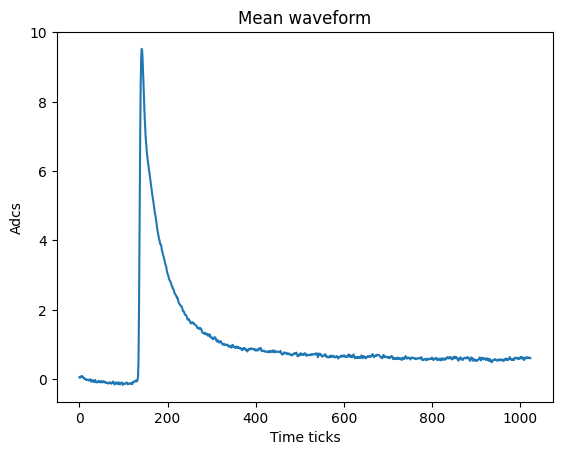

In [ ]:
mean_wf = wfset_filtered_meanwf.compute_mean_waveform()

plt.figure()
plt.plot(np.array(range(0,1024)), mean_wf.adcs, label="Mean wf")
plt.xlabel("Time ticks")
plt.ylabel("Adcs")
plt.title(f"Mean waveform")
plt.show()

Decide which integration window to use

In [ ]:
if dict_params['fixed_integral_limits'] is not None: 
    aux_limits = dict_params['fixed_integral_limits'] #(382, 406)
else: 
    aux_limits = my_integration_window(adcs_array = mean_wf.adcs, deviation_upper_limit=dict_params['deviation_upper_limit'])

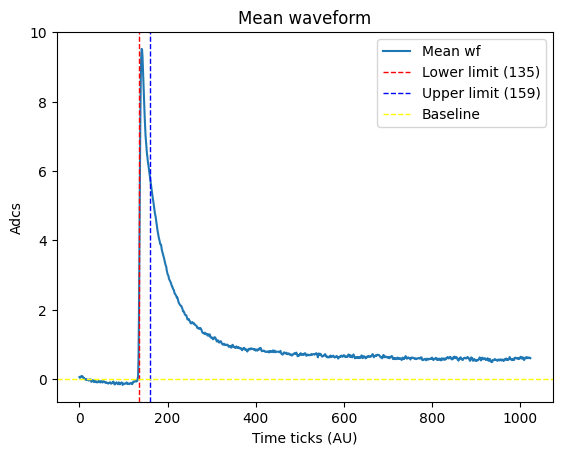

In [ ]:
plt.figure()
plt.plot(np.array(range(0,1024)), mean_wf.adcs, label="Mean wf")
plt.axvline(
    aux_limits[0],
    linestyle="--",
    color="red",
    linewidth=1,
    label=f"Lower limit ({aux_limits[0]:.0f})"
)

plt.axvline(
    aux_limits[1],
    linestyle="--",
    color="blue",
    linewidth=1,
    label=f"Upper limit ({aux_limits[1]:.0f})"
)


if dict_params['deviation_upper_limit'] is not None:
    plt.axhline(dict_params['deviation_upper_limit'] * np.max(mean_wf.adcs), 
                linestyle='--', 
                color ='orange', 
                linewidth = 1, 
                label = f"adcs threshold ({dict_params['deviation_upper_limit']*100:.0f}% peak)")

plt.axhline(0, 
            linestyle='--', 
            color ='yellow', 
            linewidth = 1, 
            label = f"Baseline")

plt.legend()
plt.xlabel("Time ticks (AU)")
plt.ylabel("Adcs")
plt.title(f"Mean waveform")
# plt.xlim(350,500)
plt.show()

INTEGRATION ANALYSIS

In [ ]:
integration_analysis_label = 'integration_analysis'

integrator_input_parameters = IPDict({
        'baseline_analysis': null_baseline_analysis_label,
        'inversion': False,
        'int_ll': aux_limits[0],
        'int_ul': aux_limits[1],
        'amp_ll': aux_limits[0],
        'amp_ul': aux_limits[1]
    })

checks_kwargs = IPDict({'points_no': wfset_filtered.points_per_wf})

_ = wfset_filtered.analyse(
    integration_analysis_label,
    WindowIntegrator,
    integrator_input_parameters,
    checks_kwargs=checks_kwargs,
    overwrite=True
)

CALIBRATION HISTOGRAM 

In [ ]:
hist_domain, hist_nbins, hist_bins_width = auto_histogram(wfset_filtered, integration_analysis_label, show_results=False)

In [ ]:
import inspect
print(inspect.signature(fit_peaks_of_ChannelWsGrid))

(channel_ws_grid: waffles.data_classes.ChannelWsGrid.ChannelWsGrid, max_peaks: int, prominence: float, initial_percentage: float = 0.1, percentage_step: float = 0.1, return_last_addition_if_fail: bool = False, fit_type: str = 'independent_gaussians', half_points_to_fit: int = 2, std_increment_seed_fallback: float = 100.0, ch_span_fraction_around_peaks: float = 0.05, verbose: bool = False) -> bool


In [ ]:
print("vgain =", vgain)
print("dict_params =", dict_params)
print("max_peaks =", dict_params["max_peaks"])
print("prominence =", dict_params["prominence"])
print("fixed_integral_limits =", dict_params["fixed_integral_limits"])

vgain = 2300
dict_params = {'baseline_timeticks_limit': 120, 'deviation_upper_limit': None, 'fixed_integral_limits': [135, 159], 'heatmap_min': -170, 'heatmap_max': 550, 'adcs_threshold': 43, 'n_std_baseline': 1, 'max_peaks': 3, 'prominence': 0.6, 'initial_percentage': 0.1, 'percentage_step': 0.2, 'ch_span_fraction_around_peaks': 0.05, 'time_range_afterpulse_for_meanwf': [220, -1]}
max_peaks = 3
prominence = 0.6
fixed_integral_limits = [135, 159]


In [ ]:
my_grid = coldbox_single_channel_grid(wfset_filtered, config_channel=channel)

my_grid.compute_calib_histos(
            bins_number=hist_nbins, 
            domain=hist_domain, 
            variable='integral',
            analysis_label=integration_analysis_label
        )

fit_peaks_of_ChannelWsGrid(
        my_grid,
        max_peaks=dict_params['max_peaks'], 
        prominence=float(dict_params['prominence']), 
        initial_percentage=dict_params['initial_percentage'],
        percentage_step=dict_params['percentage_step'],
        return_last_addition_if_fail=True,
        fit_type='multigauss_iminuit',
        #fit_type='independent_gaussians', # try if the fit takes too many peaks
        #weigh_fit_by_poisson_sigmas=True,
        ch_span_fraction_around_peaks=dict_params['ch_span_fraction_around_peaks']
    )


# # If you want to play on parameters manually
# fit_peaks_of_ChannelWsGrid(
#     my_grid,
#     max_peaks=7,
#     prominence=0.5,
#     initial_percentage=0.1,
#     percentage_step=0.02,
#     return_last_addition_if_fail=True,
#     fit_type='multigauss_iminuit',
#     weigh_fit_by_poisson_sigmas=True,
#     ch_span_fraction_around_peaks=0.05
# )



fig = plot_ChannelWsGrid(
    my_grid, 
    mode='calibration',
    plot_peaks_fits=True,           
    plot_sum_of_gaussians=True      
)

output_parameters = print_correlated_gaussians_fit_parameters(my_grid, parameters_conversion=True, show=True)

annotation_text = build_calibration_annotation(
            output_parameters,
            hist_domain,
            hist_nbins,
            hist_bins_width
        )

fig.add_annotation(
    text=annotation_text,
    xref = f"x domain" ,
    yref = f"y domain" ,
    x=0.98,
    y=1,
    showarrow=False,
    align="left",
    font=dict(size=15),  
    bgcolor="rgba(255,255,255,0.85)",
    borderwidth=1
)

fig.update_layout(title=f"channel {channel} - vgain {vgain} - led {led}")


output_dir = os.path.expanduser(f"~/cathode_plots/{membrane}_ch{channel}")
os.makedirs(output_dir, exist_ok=True)


png_file = os.path.join(
    output_dir,
    f"{membrane}_ch{channel}_vgain{vgain:04d}_led{led}.png"
)

fig.write_image(png_file, scale=3)

print(f"Saved PNG: {png_file}")

fig.show()

Peaks found: 7
Gaussian Mean: [(-195.9031202632779, 0.38689231442266175), (1538.659462818719, np.float64(0.5471721279832584)), (3273.2220459007162, np.float64(0.6701559611942066)), (5007.784628982713, np.float64(0.7738350515494467)), (6742.34721206471, np.float64(0.8651776474741695)), (8476.909795146707, np.float64(0.9477573721007618)), (10211.472378228704, np.float64(1.023697079732938))]
Gaussian Std: [(516.8063059640522, 0.38676337638884206), (np.float64(1325.7945422685034), np.float64(0.3868665552836666)), (np.float64(1802.3244931847569), np.float64(0.3868750376657613)), (np.float64(2176.9281084037734), np.float64(0.3868781837879415)), (np.float64(2495.928364273136), np.float64(0.386879824281896)), (np.float64(2778.542929308078), np.float64(0.38688083127639944)), (np.float64(3034.9535779699586), np.float64(0.3868815123378207))]
Gaussian Amplitude: [(81.568709243052, 0.3823347201595908), (92.45215913959731, 0.37670456451377277), (42.35761209486948, 0.36991276513945337), (12.384333232

In [ ]:
# To count how many wfs we have per peak and see if they are balanced
print(f"Channel {channel} - led {led} - vgain {vgain}")
calibration_histogram_peak_counts(wfset_filtered, output_parameters)

Channel 19 - led 920 - vgain 2300
0 peak: 2800 counts
1 peak: 6717 counts


Compute Single Photon electron amplitude

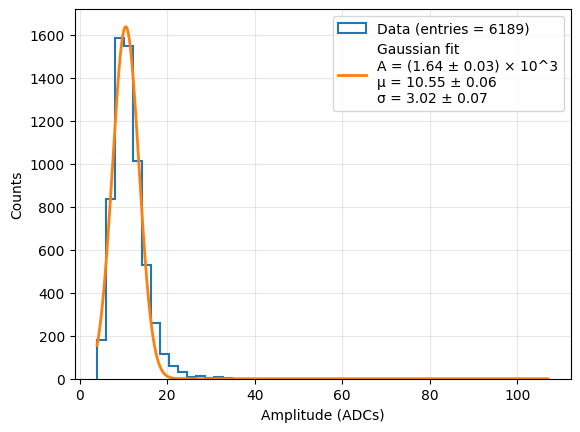

In [ ]:
spe_result = spe_amplitude_computation(wfset_filtered, channel, output_parameters, show_persistance = False, show_spe_hist = True)

In [ ]:
import inspect
print(inspect.getsource( spe_amplitude_computation))

def spe_amplitude_computation(wfset_filtered, channel, output_parameters, n_sigma_spe_selection : float = 1., integration_analysis_label : str = 'integration_analysis', show_persistance: bool = False, show_spe_hist: bool = True):
    wfset_spe = WaveformSet.from_filtered_WaveformSet(wfset_filtered, spe_filter_integral, spe_integral_mean = output_parameters['params']['mean'][1][0], spe_integral_sigma = output_parameters['params']['std'][1][0], integration_analysis_label = integration_analysis_label, n_sigma = n_sigma_spe_selection)

    if show_persistance: 
        persistance_plot_helper(wfset_spe, channel, ymin = -100, ymax = 100, adc_bins = 1000, show=show_persistance)

    amplitude_list = []
    for wf in wfset_spe.waveforms:
        amplitude_list.append(wf.analyses[integration_analysis_label].result['amplitude'])

    data = np.array(amplitude_list)

    counts, bin_edges = np.histogram(data, bins=50)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    A0 = np.max(counts

Compute dynamic range

In [ ]:
dynamic_range_computation(spe_result['mean'][0])

np.float64(1553.2467661767905)

In [ ]:
import inspect
print(inspect.getsource(dynamic_range_computation))

def dynamic_range_computation(spe_adc, daphne_range: int = 2**14): # no cold electronic saturation
    return daphne_range/spe_adc



Saving all results for each channel and vgain

In [ ]:
csv_file = f"{membrane}_ch{channel}_results.csv"

new_row = {
    "channel": channel,
    "vgain": vgain,
    "snr": output_parameters["snr"],
    "spe_amplitude": spe_result["mean"][0],
    "dynamic_range": dynamic_range_computation(spe_result["mean"][0])
}

# load existing dataframe if it exists
if os.path.exists(csv_file):
    df = pd.read_csv(csv_file)
else:
    df = pd.DataFrame()

# append new row
df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

# optional: remove duplicates for same vgain
df = df.drop_duplicates(subset=["channel", "vgain"], keep="last")

# sort nicely
df = df.sort_values("vgain")

# save updated file
df.to_csv(csv_file, index=False)

df

,channel,vgain,snr,spe_amplitude,dynamic_range
0,19,500,6.277747,98.578284,166.202934
1,19,700,7.045072,72.507742,225.962078
2,19,900,4.183665,99.544515,164.589681
3,19,1300,4.063048,52.425424,312.520121
4,19,1700,4.195715,21.217025,772.210067
5,19,2100,3.587107,13.764320,1190.323968
7,19,2300,3.356311,10.548227,1553.246766


In [ ]:
df18 = pd.read_csv("M5_ch18_results.csv")
df19 = pd.read_csv("M5_ch19_results.csv")
df20 = pd.read_csv("M6_ch20_results.csv")
df21 = pd.read_csv("M6_ch21_results.csv")

In [ ]:
df16 = pd.read_csv("M5_ch16_results.csv")
df17 = pd.read_csv("M5_ch17_results.csv")
df18 = pd.read_csv("M6_ch18_results.csv")
df19 = pd.read_csv("M6_ch19_results.csv")


Saved plot: /afs/cern.ch/user/m/mamollov/cathode_plots/performance_plots/SNR_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png


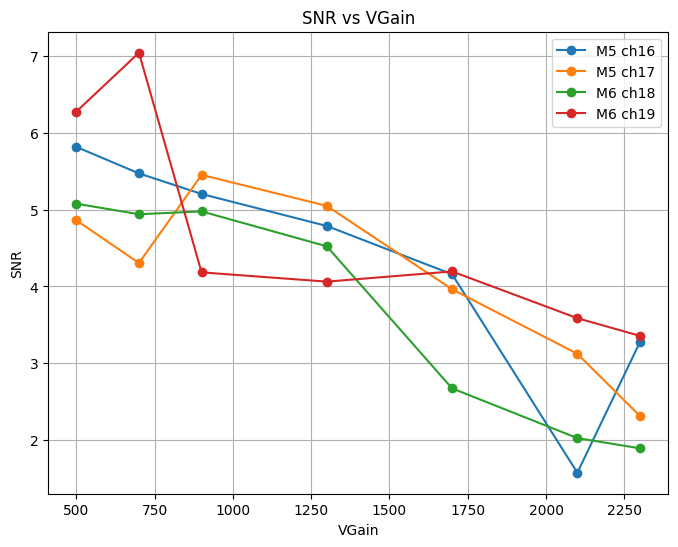

In [ ]:
plt.figure(figsize=(8,6))

for df, label in [
    (df16, "M5 ch16"),
    (df17, "M5 ch17"),
    (df18, "M6 ch18"),
    (df19, "M6 ch19"),
]:

    df = df.sort_values("vgain")

    plt.plot(
        df["vgain"],
        df["snr"],
        marker="o",
        label=label
    )

plt.xlabel("VGain")
plt.ylabel("SNR")
plt.title("SNR vs VGain")

plt.grid(True)
plt.legend()

output_dir = os.path.expanduser("~/cathode_plots/performance_plots")
os.makedirs(output_dir, exist_ok=True)

save_file = os.path.join(
    output_dir,
    "SNR_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png"
)
plt.savefig(save_file, dpi=300, bbox_inches="tight")

print(f"Saved plot: {save_file}")


plt.show()

Saved plot: /afs/cern.ch/user/m/mamollov/cathode_plots/performance_plots/DR_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png


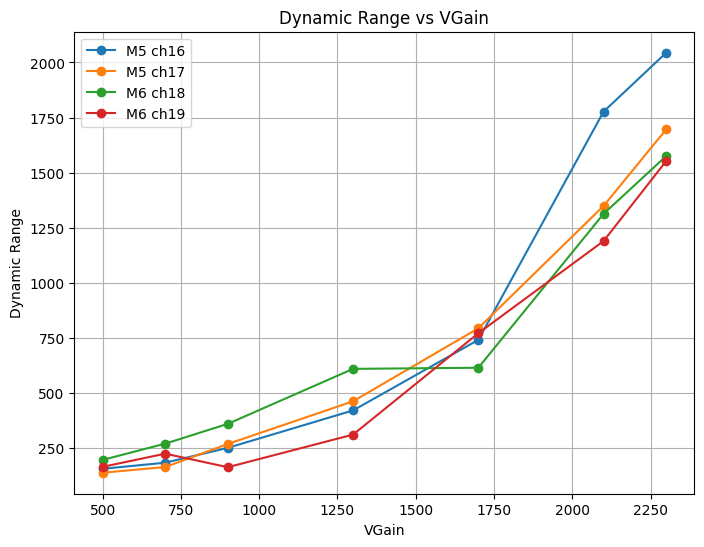

In [ ]:
plt.figure(figsize=(8,6))

for df, label in [
    (df16, "M5 ch16"),
    (df17, "M5 ch17"),
    (df18, "M6 ch18"),
    (df19, "M6 ch19"),
]:


    df = df.sort_values("vgain")

    plt.plot(
        df["vgain"],
        df["dynamic_range"],
        marker="o",
        label=label
    )

plt.xlabel("VGain")
plt.ylabel("Dynamic Range")
plt.title("Dynamic Range vs VGain")

plt.grid(True)
plt.legend()

output_dir = os.path.expanduser("~/cathode_plots/performance_plots")
os.makedirs(output_dir, exist_ok=True)

save_file = os.path.join(
    output_dir,
    "DR_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png"
)

plt.savefig(save_file, dpi=300, bbox_inches="tight")

print(f"Saved plot: {save_file}")

plt.show()

Saved plot: /afs/cern.ch/user/m/mamollov/cathode_plots/performance_plots/SPE_amplitude_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png


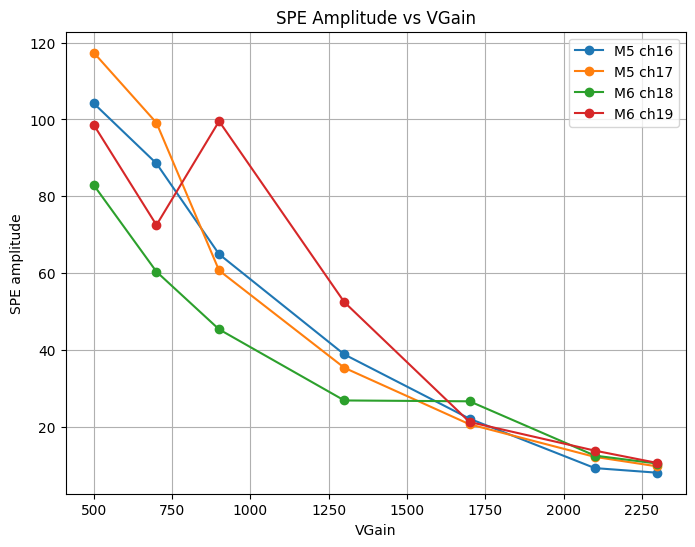

In [ ]:
plt.figure(figsize=(8,6))

for df, label in [
    (df16, "M5 ch16"),
    (df17, "M5 ch17"),
    (df18, "M6 ch18"),
    (df19, "M6 ch19"),
]:

    df = df.sort_values("vgain")

    plt.plot(
        df["vgain"],
        df["spe_amplitude"],
        marker="o",
        label=label
    )

plt.xlabel("VGain")
plt.ylabel("SPE amplitude")
plt.title("SPE Amplitude vs VGain")

plt.grid(True)
plt.legend()

output_dir = os.path.expanduser("~/cathode_plots/performance_plots")
os.makedirs(output_dir, exist_ok=True)

save_file = os.path.join(
    output_dir,
    "SPE_amplitude_vs_VGain_M5ch16_M5ch17_M6ch18_M6ch19.png"
)

plt.savefig(save_file, dpi=300, bbox_inches="tight")

print(f"Saved plot: {save_file}")

plt.show()

Saved plot: /afs/cern.ch/user/m/mamollov/cathode_plots/performance_plots/SNR_vs_SPE_amplitude_M5ch18_M5ch19_M6ch20_M6ch21.png


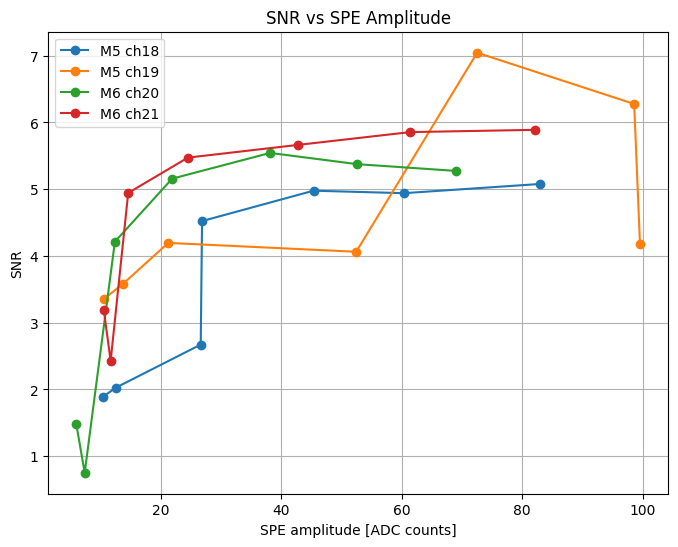

In [ ]:
import os
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for df, label in [
    (df18, "M5 ch18"),
    (df19, "M5 ch19"),
    (df20, "M6 ch20"),
    (df21, "M6 ch21"),
]:

    df = df.sort_values("spe_amplitude")

    plt.plot(
        df["spe_amplitude"],
        df["snr"],
        marker="o",
        label=label
    )

plt.xlabel("SPE amplitude [ADC counts]")
plt.ylabel("SNR")
plt.title("SNR vs SPE Amplitude")

plt.grid(True)
plt.legend()

output_dir = os.path.expanduser("~/cathode_plots/performance_plots")
os.makedirs(output_dir, exist_ok=True)

save_file = os.path.join(
    output_dir,
    "SNR_vs_SPE_amplitude_M5ch18_M5ch19_M6ch20_M6ch21.png"
)

plt.savefig(save_file, dpi=300, bbox_inches="tight")

print(f"Saved plot: {save_file}")

plt.show()

Saved plot: /afs/cern.ch/user/m/mamollov/cathode_plots/performance_plots/Dynamic_range_vs_SPE_amplitude_M5ch18_M5ch19_M6ch20_M6ch21.png


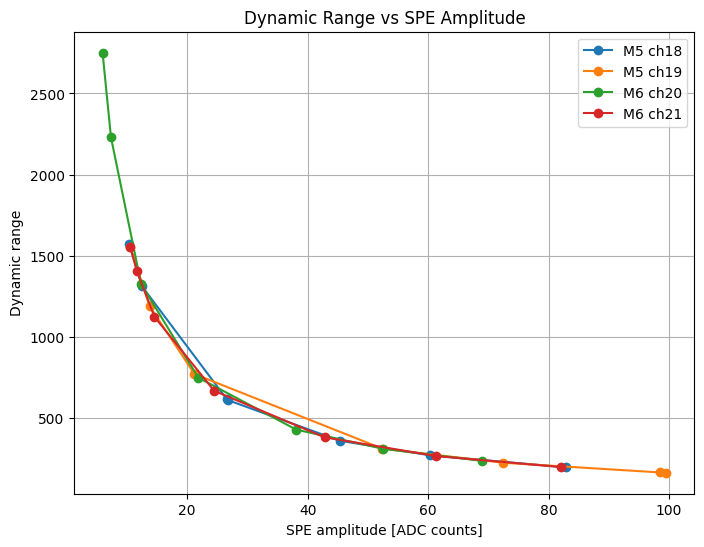

In [ ]:
import os
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))


for df, label in [
    (df18, "M5 ch18"),
    (df19, "M5 ch19"),
    (df20, "M6 ch20"),
    (df21, "M6 ch21"),
]:

    df = df.sort_values("spe_amplitude")

    plt.plot(
        df["spe_amplitude"],
        df["dynamic_range"],
        marker="o",
        label=label
    )

plt.xlabel("SPE amplitude [ADC counts]")
plt.ylabel("Dynamic range")
plt.title("Dynamic Range vs SPE Amplitude")

plt.grid(True)
plt.legend()

output_dir = os.path.expanduser("~/cathode_plots/performance_plots")
os.makedirs(output_dir, exist_ok=True)

save_file = os.path.join(
    output_dir,
    "Dynamic_range_vs_SPE_amplitude_M5ch18_M5ch19_M6ch20_M6ch21.png"
)

plt.savefig(save_file, dpi=300, bbox_inches="tight")

print(f"Saved plot: {save_file}")

plt.show()